# 02 - Baseline EEG feature extraction

Demonstrate the BrainFlow `DataFilter`-based pipeline (`app/eeg/features.py`) on synthetic data and inspect the agent's observation vector.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from app.brain_sim.nmm import MultiChannelBrain
from app.brain_sim.photic_input import PhoticInputConfig, StrobeParams, strobe_to_cortical_input
from app.eeg.features import extract_features, feature_vector, FEATURE_NAMES
from app.eeg.montage import OCCIPITAL_ALPHA
SR = 500

## 1. Eyes-closed-like baseline vs photic drive

In [2]:
brain = MultiChannelBrain(n_channels=8, alpha_hz=10.0, sampling_rate=SR, seed=42)
brain.run(2.0)
baseline = brain.run(4.0)
snap_base = extract_features(baseline, SR, OCCIPITAL_ALPHA)
print('Baseline features:', snap_base)

config = PhoticInputConfig(cortical_gain=600.0, base_resonance_hz=6.0, resonance_width_hz=3.0)
strobe = StrobeParams(enabled=True, frequency_hz=6.0, fill=0.3, brightness=0.5)
brain2 = MultiChannelBrain(n_channels=8, alpha_hz=10.0, sampling_rate=SR, seed=42)
brain2.run(2.0)
driven = brain2.run(4.0, photic_fn=lambda t: strobe_to_cortical_input(t, strobe, config))
snap_drive = extract_features(driven, SR, OCCIPITAL_ALPHA)
print('Driven features:', snap_drive)

/home/sim-rn/second_ssd/study/adaptive_neuro_stimulation_sleep/venv/lib/python3.10/site-packages/brainflow/data_filter.py:163: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  import pkg_resources


Baseline features: FeatureSnapshot(t_ms=0, alpha_pwr=0.12999199163279065, theta_pwr=0.0012075612765091938, beta_pwr=0.0022452956638053445, hypnagogic_theta_pwr=0.00029375708508021063, sigma_pwr=0.007924694789191068, theta_alpha_ratio=0.009289505155910661, emg_rms=8.72967137374183e-05, eog_energy=5.939243204287717, railed_pct=4.95, n_samples=2000)
Driven features: FeatureSnapshot(t_ms=0, alpha_pwr=0.18100121057143573, theta_pwr=0.005975578422380462, beta_pwr=0.005362019874380017, hypnagogic_theta_pwr=0.004574989294992762, sigma_pwr=0.027111220605855166, theta_alpha_ratio=0.03301402462161471, emg_rms=0.00010654861530554183, eog_energy=6.145157014796747, railed_pct=3.25, n_samples=2000)


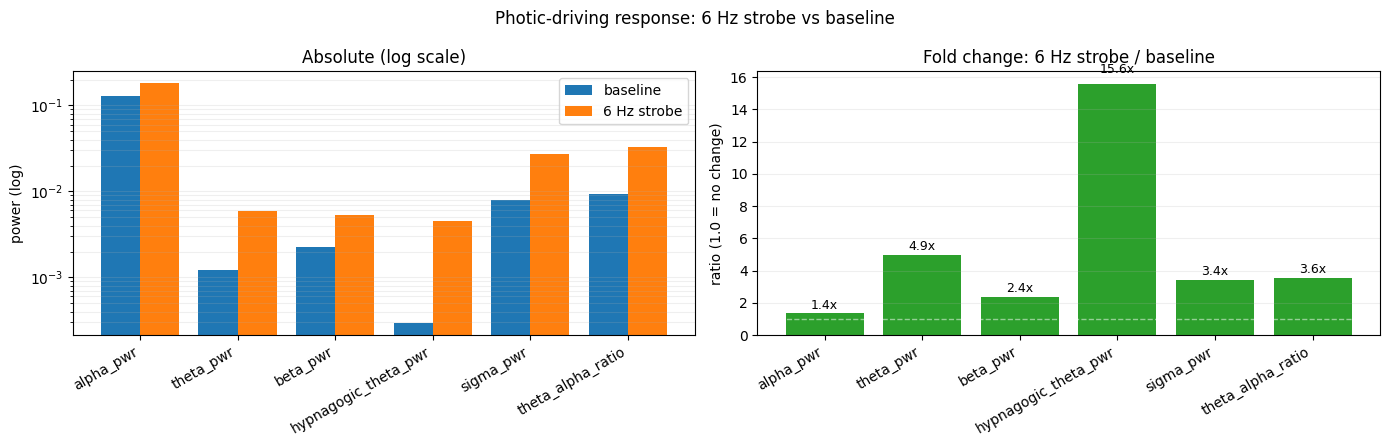


Electrode-quality probes (should not change between conditions):
  feature          baseline  6 Hz strobe
  emg_rms            0.0001       0.0001
  eog_energy         5.9392       6.1452
  railed_pct         4.9500       3.2500


In [3]:
# The interesting story is the FOLD CHANGE (drive / baseline), not the
# absolute values - features span ~4 orders of magnitude (alpha_pwr ~0.18,
# hypnagogic_theta_pwr ~0.005, theta_pwr ~0.006). On a linear axis the big
# bands hide the small ones; on a log axis they're all readable. We pair the
# log-scale absolute plot with a fold-change bar chart that makes the strobe
# entrainment headline (~15x boost in hypnagogic theta) immediately obvious.
BAND_FEATURES = [
    'alpha_pwr', 'theta_pwr', 'beta_pwr',
    'hypnagogic_theta_pwr', 'sigma_pwr', 'theta_alpha_ratio',
]
QC_FEATURES = ['emg_rms', 'eog_energy', 'railed_pct']

by_name_base  = dict(zip(FEATURE_NAMES, feature_vector(snap_base)))
by_name_drive = dict(zip(FEATURE_NAMES, feature_vector(snap_drive)))

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
x = np.arange(len(BAND_FEATURES))

# Panel A: absolute values, log y so small bands stay visible.
ax = axes[0]
ax.bar(x - 0.2, [by_name_base[f]  for f in BAND_FEATURES], width=0.4,
        label='baseline')
ax.bar(x + 0.2, [by_name_drive[f] for f in BAND_FEATURES], width=0.4,
        label='6 Hz strobe')
ax.set_yscale('log')
ax.set_xticks(x); ax.set_xticklabels(BAND_FEATURES, rotation=30, ha='right')
ax.set_title('Absolute (log scale)'); ax.set_ylabel('power (log)')
ax.legend(); ax.grid(alpha=0.2, axis='y', which='both')

# Panel B: fold change = drive / baseline. Horizontal line at 1.0 = no change.
ax = axes[1]
ratios = [by_name_drive[f] / by_name_base[f] if by_name_base[f] > 1e-9 else np.nan
          for f in BAND_FEATURES]
colors = ['tab:green' if r >= 1.0 else 'tab:red' for r in ratios]
bars = ax.bar(x, ratios, color=colors)
ax.axhline(1.0, color='white', alpha=0.5, lw=1, linestyle='--')
ax.set_xticks(x); ax.set_xticklabels(BAND_FEATURES, rotation=30, ha='right')
ax.set_title('Fold change: 6 Hz strobe / baseline')
ax.set_ylabel('ratio (1.0 = no change)'); ax.grid(alpha=0.2, axis='y')
# Annotate each bar with its multiplier - hard to miss the 15x.
for bar, r in zip(bars, ratios):
    if np.isfinite(r):
        ax.text(bar.get_x() + bar.get_width() / 2, r * 1.03,
                f'{r:.1f}x', ha='center', va='bottom', fontsize=9)

fig.suptitle('Photic-driving response: 6 Hz strobe vs baseline')
fig.tight_layout(); plt.show()

# QC features as a one-line sanity table - electrode-quality probes, not
# the entrainment comparison. They should look ~the same in both conditions.
print('\nElectrode-quality probes (should not change between conditions):')
print(f"  {'feature':<14s} {'baseline':>10s} {'6 Hz strobe':>12s}")
for f in QC_FEATURES:
    print(f"  {f:<14s} {by_name_base[f]:10.4f} {by_name_drive[f]:12.4f}")
